<a href="https://colab.research.google.com/github/SomTu/01RAD/blob/main/HW/01RAD_Ex03_HW_Satransky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex03_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 03: How much timber is in a tree? (shortleaf pines)

Foresters estimate the volume of timber in a standing tree from its diameter, which is easy to measure. The file `shortleaf.txt` contains 70 shortleaf pines (*Pinus echinata*) with the diameter at breast height `Diam` (inches) and the timber volume `Vol` (cubic feet).

Tools of Lectures 3 and 4 (slides pp. 27–64 of `lectures/01RAD_2024.pdf`): the decomposition $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$, the **coefficient of determination** $R^2$, the $F$-test and the **ANOVA table**, the **model through the origin** with $s_n^2 = \mathrm{SSE}/(n-1)$ and the uncentred $R^2$, the **confidence interval** for $\mathrm{E}\,Y_0$ and the **prediction interval** for $Y_0$, **studentized residuals** $\widehat{r}_i$ and residual plots. Exercise 03 shows all of them in code.

## Submission
Work through the tasks in this notebook (code plus short written answers in markdown cells; Python or R, as you prefer). **Deadline: Sunday 18 October 2026, 23:59**, six days after the exercise and before the next one. Submit through GitHub: fork `francji1/01RAD`, save the notebook into the `HW/` folder as `01RAD_Ex03_HW_<Surname>.ipynb`, with your surname in place of `<Surname>` and without the brackets, for example `01RAD_Ex03_HW_Novak.ipynb` (team: surnames joined by an underscore), and open a pull request to `main`. The pull request should add your one file only; do not modify or delete other files. One submitted solution will be discussed at the beginning of the next exercise.

Useful calls: `sm.stats.anova_lm(model)`, `model.rsquared`, `model.fvalue`, `model.f_pvalue`, `smf.ols('Vol ~ I(Diam**2)', data=pines)` (a transformed regressor in the formula), `smf.ols('Vol ~ Diam - 1', data=pines)` (no intercept), `model.get_prediction(new_data).summary_frame(alpha=0.05)`, `model.get_influence().resid_studentized_internal`, `stats.t.ppf`, `stats.f.sf`.

## Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid', palette='deep')

url_pines = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/shortleaf.txt'
pines = pd.read_csv(url_pines, sep='\t')
print(f'Rows: {pines.shape[0]}, columns: {pines.shape[1]}')
pines.describe().T

Rows: 70, columns: 2


,count,mean,std,min,25%,50%,75%,max
Diam,70.0,11.184286,4.132713,4.4,8.175,10.8,14.300,23.4
Vol,70.0,34.895714,29.906499,2.0,14.350,27.0,44.725,163.5


## Task 01 - Straight line and its ANOVA table
Fit the regression of `Vol` on `Diam`. Compute $\mathrm{SST}$, $\mathrm{SSR}$, $\mathrm{SSE}$, the degrees of freedom, the mean squares, $F$ and its $p$-value by hand, arrange them in the ANOVA table and compare with `anova_lm` (R: `anova`). Compute $R^2$ in three ways ($\mathrm{SSR}/\mathrm{SST}$, $1 - \mathrm{SSE}/\mathrm{SST}$, $\rho^2(\mathbf{x}, \mathbf{y})$) and verify $F = T_1^2$.

In [14]:
n = len(pines)
y = pines['Vol']
m1 = smf.ols('Vol ~ Diam', data=pines).fit()

# Sums of squares
SST = np.sum((y - y.mean())**2)
SSE = np.sum(m1.resid**2)
SSR = np.sum((m1.fittedvalues - y.mean())**2)

# Degrees of freedom, mean squares, F, p-value
df_R, df_E, df_T = 1, n - 2, n - 1
MSR, MSE = SSR / df_R, SSE / df_E
F = MSR / MSE
p_F = stats.f.sf(F, df_R, df_E)

# ANOVA table by hand
anova_hand = pd.DataFrame(
    {'df': [df_R, df_E, df_T],
     'SS': [SSR, SSE, SST],
     'MS': [MSR, MSE, np.nan],
     'F': [F, np.nan, np.nan],
     'p-value': [p_F, np.nan, np.nan]},
    index=['Regression (Diam)', 'Residual', 'Total'])
print(anova_hand.round(2))
print(sm.stats.anova_lm(m1).round(2))

# R^2 three ways
R2_a = SSR / SST
R2_b = 1 - SSE / SST
R2_c = np.corrcoef(pines['Diam'], y)[0, 1]**2
print("R2:", f'{R2_a:.2f} {R2_b:.2f} {R2_c:.2f} {m1.rsquared:.2f}')

# F = T^2
T = m1.tvalues['Diam']
print("F-stat:", f'{F:.2f} {T**2:.2f}', np.isclose(F, T**2))

                   df        SS        MS       F  p-value
Regression (Diam)   1  55082.65  55082.65  564.88      0.0
Residual           68   6630.86     97.51     NaN      NaN
Total              69  61713.51       NaN     NaN      NaN
            df    sum_sq   mean_sq       F  PR(>F)
Diam       1.0  55082.65  55082.65  564.88     0.0
Residual  68.0   6630.86     97.51     NaN     NaN
R2: 0.89 0.89 0.89 0.89
F-stat: 564.88 564.88 True


## Task 02 - Is a large $R^2$ a good model?
$R^2$ of Task 01 is close to 0.9. Plot the data with the fitted line and draw the studentized residuals against `Diam` and against the fitted values, and a Q-Q plot. What do the plots show about linearity and about constant variance? What does the fitted line predict for the thinnest trees in the data, and does that make physical sense? Relate your answer to the part of Lecture 4 on checking model adequacy.

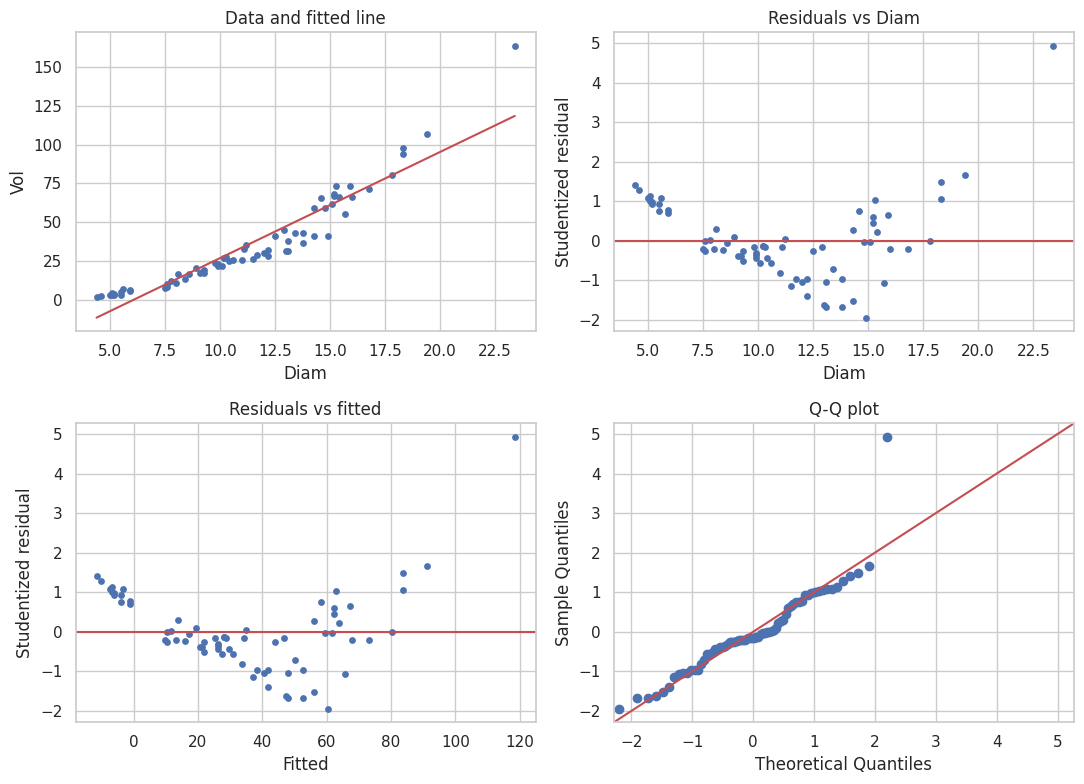

   Diam  Vol  Fitted
0   4.4  2.0  -11.49
1   4.6  2.2  -10.12
2   5.0  3.0   -7.38
3   5.1  4.3   -6.70
4   5.1  3.0   -6.70


In [15]:
infl = m1.get_influence()
r = infl.resid_studentized_internal
fit = m1.fittedvalues

fig, ax = plt.subplots(2, 2, figsize=(11, 8))

xs = np.linspace(pines['Diam'].min(), pines['Diam'].max(), 200)
ax[0, 0].scatter(pines['Diam'], y, s=15)
ax[0, 0].plot(xs, m1.predict(pd.DataFrame({'Diam': xs})), 'r')
ax[0, 0].set(xlabel='Diam', ylabel='Vol', title='Data and fitted line')

ax[0, 1].scatter(pines['Diam'], r, s=15)
ax[0, 1].axhline(0, color='r')
ax[0, 1].set(xlabel='Diam', ylabel='Studentized residual', title='Residuals vs Diam')

ax[1, 0].scatter(fit, r, s=15)
ax[1, 0].axhline(0, color='r')
ax[1, 0].set(xlabel='Fitted', ylabel='Studentized residual', title='Residuals vs fitted')

sm.qqplot(r, line='45', ax=ax[1, 1])
ax[1, 1].set_title('Q-Q plot')

plt.tight_layout()
plt.show()

# Predictions for the thinnest trees
thin = pines.nsmallest(5, 'Diam')[['Diam', 'Vol']].assign(Fitted=lambda d: m1.predict(d))
print(thin.round(2))

# Explanation

The data seem to not be linear in the global scope, however on small subsamples they could be considered "quite linear". This correlates with the question of thinnest trees prediction, which impossibly predicts negative tree volume. If we wanted to get a general model for many different diameters, we must accept the fact that extremes could be highly outlying. If we were to model only small trees, a linear model could give us more physical answers.

From the residual plots we can see that


1.   The variance is nonconstant and increases with diameter, the requirement of homoscedasticity doesnt hold, and
2.   there is a clearly visible trend in the residuals, suggesting that a transofrmation might help with fitting a better model.



## Task 03 - A model from geometry
The volume of a cylinder or a cone is proportional to the square of the diameter (times the height, which we do not have). Fit `Vol ~ I(Diam**2)`; this is still a simple linear regression, with the regressor $x_i = \mathrm{Diam}_i^2$. Compare it with Task 01: $R^2$, $s_n$, the residual plots. Is it legitimate to compare the two $R^2$ values here, and why (think of what $\mathrm{SST}$ is in both models)?

R2:  m1 0.89  m2 0.97
s_n: m1 9.87  m2 5.52


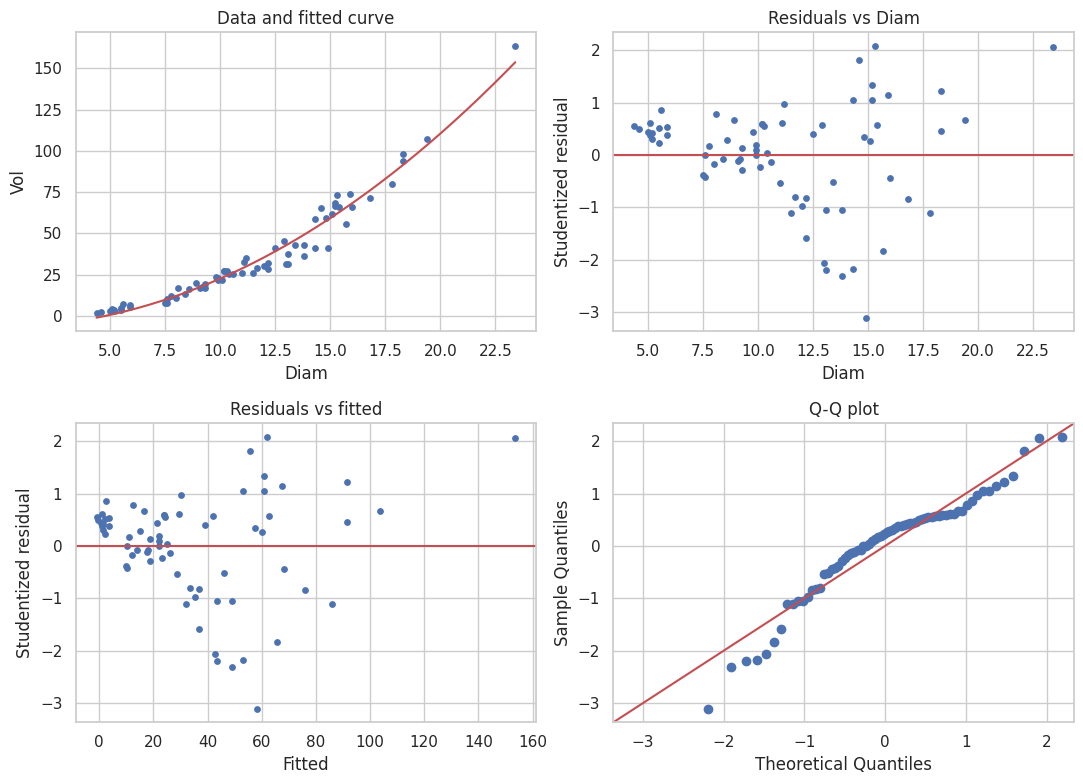

In [16]:
m2 = smf.ols('Vol ~ I(Diam**2)', data=pines).fit()
r2 = m2.get_influence().resid_studentized_internal

print(f'R2:  m1 {m1.rsquared:.2f}  m2 {m2.rsquared:.2f}')
print(f's_n: m1 {np.sqrt(m1.mse_resid):.2f}  m2 {np.sqrt(m2.mse_resid):.2f}')

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
xs = np.linspace(pines['Diam'].min(), pines['Diam'].max(), 200)
ax[0, 0].scatter(pines['Diam'], y, s=15)
ax[0, 0].plot(xs, m2.predict(pd.DataFrame({'Diam': xs})), 'r')
ax[0, 0].set(xlabel='Diam', ylabel='Vol', title='Data and fitted curve')
ax[0, 1].scatter(pines['Diam'], r2, s=15); ax[0, 1].axhline(0, color='r')
ax[0, 1].set(xlabel='Diam', ylabel='Studentized residual', title='Residuals vs Diam')
ax[1, 0].scatter(m2.fittedvalues, r2, s=15); ax[1, 0].axhline(0, color='r')
ax[1, 0].set(xlabel='Fitted', ylabel='Studentized residual', title='Residuals vs fitted')
sm.qqplot(r2, line='45', ax=ax[1, 1]); ax[1, 1].set_title('Q-Q plot')
plt.tight_layout(); plt.show()

# Explanation

It is legitimate to compare the two models using $R^2$, because of how is it computed. $R^2=\frac{\mathrm{SSR}}{\mathrm{SST}}$, SST doesnt change between the models, because the target variable doesnt change. SSR then shows the amount of explained variance.

## Task 04 - Through the origin
A tree with zero diameter has zero volume, so the model $\mathrm{Vol}_i = \beta_1 \mathrm{Diam}_i^2 + e_i$ without intercept is natural. Fit it and compute by hand $\widehat{\beta}_1 = \sum x_i y_i / \sum x_i^2$, $s_n^2 = \mathrm{SSE}/(n-1)$, the standard error of $\widehat{\beta}_1$, the decomposition $\sum y_i^2 = \sum \widehat{y}_i^2 + \sum \widehat{e}_i^2$ and the uncentred $R^2$; compare with `statsmodels`. Then compare the model with the model of Task 03: which has the larger `R-squared`, which has the smaller $s_n$, and which comparison is the fair one (Lecture 4, Remark 2.17)? Finally, test $H_0: \beta_0 = 0$ in the model of Task 03. Do the test and the geometric argument point the same way?

146953.27 146953.27
b1=0.2614 s2n=44.81 se=0.0046 R2_unc=0.9790
I(Diam ** 2)    0.2614
dtype: float64 I(Diam ** 2)    0.0046
dtype: float64 0.979 44.81
R2:  m3 0.9790  m2 0.9665
s_n: m3 6.694  m2 5.517
t=-5.79, p=0.0000
0   -8.934
1   -4.356
Name: Intercept, dtype: float64


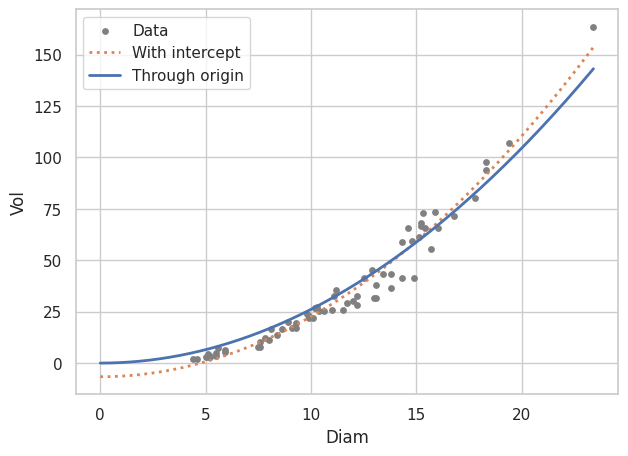

In [18]:
x = pines['Diam']**2
m3 = smf.ols('Vol ~ I(Diam**2) - 1', data=pines).fit()

# By hand
b1 = (x * y).sum() / (x**2).sum()
yhat0 = b1 * x
e0 = y - yhat0
SSE0 = (e0**2).sum()
s2n = SSE0 / (n - 1)
se_b1 = np.sqrt(s2n / (x**2).sum())

# Decomposition sum y^2 = sum yhat^2 + sum e^2 and uncentred R^2
Sy2, Syh2 = (y**2).sum(), (yhat0**2).sum()
R2_unc = Syh2 / Sy2
print(f'{Sy2:.2f} {Syh2 + SSE0:.2f}')
print(f'b1={b1:.4f} s2n={s2n:.2f} se={se_b1:.4f} R2_unc={R2_unc:.4f}')

# statsmodels
print(m3.params.round(4), m3.bse.round(4), round(m3.rsquared, 4), round(m3.mse_resid, 2))

# Comparison with Task 03
print(f'R2:  m3 {m3.rsquared:.4f}  m2 {m2.rsquared:.4f}')
print(f's_n: m3 {np.sqrt(m3.mse_resid):.3f}  m2 {np.sqrt(m2.mse_resid):.3f}')

# H0: beta0 = 0 in Task 03 model
print(f"t={m2.tvalues['Intercept']:.2f}, p={m2.pvalues['Intercept']:.4f}")
print(m2.conf_int().loc['Intercept'].round(3))

xs = np.linspace(0, pines['Diam'].max(), 200)
grid = pd.DataFrame({'Diam': xs})

plt.figure(figsize=(7, 5))
plt.scatter(pines['Diam'], y, s=15, color='gray', label='Data')
plt.plot(xs, m2.predict(grid), ':', color='C1', lw=2, label='With intercept')
plt.plot(xs, m3.predict(grid), '-', color='C0', lw=2, label='Through origin')
plt.xlabel('Diam'); plt.ylabel('Vol'); plt.legend()
plt.show()

The model through the origin has the larger $R^2$ ($0.979$ vs $0.9665$), but this comparison is not fair: its uncentred $R^2$ divides by $\sum y_i^2$ rather than by $\mathrm{SST} = \sum (y_i - \bar{y})^2$, so the two values measure different things. This would be very clearly seen when the target variable would have large $\bar{y}$, since the SST would measure deviation from $\bar{y}$, while the model through origin would measure the square of the distance from 0. The denominator in the $R^2$ computation would then be much bigger in the model through origin.

The fair comparison is $s_n$, which is on the scale of $\mathrm{Vol}$ for both models, and there the model with intercept is better ($5.52$ vs $6.69$). The test of $H_0: \beta_0 = 0$ in the model with intercept rejects it ($t = -5.79$, $p \approx 0$, $95\%$ CI $(-8.93, -4.36)$), so the test and the geometric argument (zero diameter implies zero volume) point in opposite directions. The explanation is that the data cover only a limited range of diameters, so the fitted intercept ($\hat{\beta}_0 \approx -6.6$) describes the best line within that range and not the behaviour at $\mathrm{Diam} = 0$. The through-origin model is physically sensible, but it fits the observed range slightly worse.

## Task 05 - Predictions
Choose one of the models of Tasks 03 and 04 and justify the choice in two sentences. For trees with diameters 8, 15 and 30 inches compute by hand the 95 % confidence interval for the mean volume and the 95 % prediction interval for the volume of one tree (with $n-2$ or $n-1$ degrees of freedom, according to your model), and check the numbers with `get_prediction`. Which of the three diameters is an extrapolation? Add the prediction of the straight line of Task 01 at 30 inches and comment on the difference.

# Choice

I choose the intercept model due to its better $s_n$ on the entire domain, while assuming that the negative predictions near 0 will not pose much actual problems when computing confindence intervals for diameters 8+ in.


In [24]:
d0 = np.array([8, 15, 30])
x = pines['Diam']**2
x0 = d0**2

xbar, Sxx = x.mean(), ((x - x.mean())**2).sum()
b1 = ((x - xbar) * (y - y.mean())).sum() / Sxx
b0 = y.mean() - b1 * xbar
s = np.sqrt(((y - b0 - b1 * x)**2).sum() / (n - 2))
tc = stats.t.ppf(0.975, n - 2)

fit = b0 + b1 * x0
h = 1 / n + (x0 - xbar)**2 / Sxx
by_hand = pd.DataFrame({
    'Diam': d0, 'fit': fit,
    'CI_low': fit - tc * s * np.sqrt(h),     'CI_up': fit + tc * s * np.sqrt(h),
    'PI_low': fit - tc * s * np.sqrt(1 + h), 'PI_up': fit + tc * s * np.sqrt(1 + h)})
print('Prediction by hand:')
print(by_hand.round(2))

print("\nPrediction from get_prediction(): ")
# Check
sf = m2.get_prediction(pd.DataFrame({'Diam': d0})).summary_frame(alpha=0.05)
print(sf.round(2))

print("\nMinimum:", pines['Diam'].min(), "--- Maximum:", pines['Diam'].max())
print("\nExtrapolation check for straight line model: ")
# Extrapolation check and straight line of Task 01 at 30 in

print(m1.get_prediction(pd.DataFrame({'Diam': [30]})).summary_frame(alpha=0.05).round(2))

Prediction by hand:
   Diam     fit  CI_low   CI_up  PI_low   PI_up
0     8   12.09   10.42   13.76    0.95   23.22
1    15   59.21   57.50   60.92   48.07   70.35
2    30  256.78  246.69  266.87  241.85  271.72

Prediction from get_prediction(): 
     mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0   12.09     0.84          10.42          13.76          0.95         23.22
1   59.21     0.86          57.50          60.92         48.07         70.35
2  256.78     5.06         246.69         266.87        241.85        271.72

Minimum: 4.4 --- Maximum: 23.4

Extrapolation check for straight line model: 
     mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  163.53     5.54         152.48         174.59        140.94        186.13


## Task 06 - Bands
Plot the data with the fitted curve of your model on the original scale (`Diam` on the horizontal axis) together with the 95 % confidence band for the mean and the 95 % prediction band. Where are the bands narrowest and why? Why does the prediction band not shrink towards the curve if we measured many more trees?

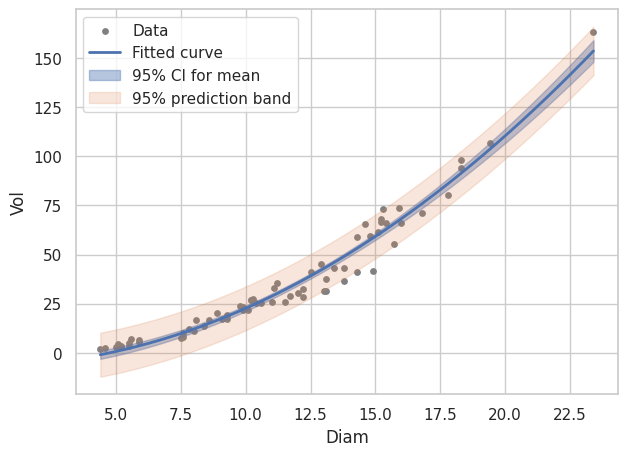

In [20]:
grid = pd.DataFrame({'Diam': np.linspace(pines['Diam'].min(), pines['Diam'].max(), 200)})
sf = m2.get_prediction(grid).summary_frame(alpha=0.05)

plt.figure(figsize=(7, 5))
plt.scatter(pines['Diam'], y, s=15, color='gray', label='Data')
plt.plot(grid['Diam'], sf['mean'], 'C0', lw=2, label='Fitted curve')
plt.fill_between(grid['Diam'], sf['mean_ci_lower'], sf['mean_ci_upper'],
                 color='C0', alpha=0.4, label='95% CI for mean')
plt.fill_between(grid['Diam'], sf['obs_ci_lower'], sf['obs_ci_upper'],
                 color='C1', alpha=0.2, label='95% prediction band')
plt.xlabel('Diam'); plt.ylabel('Vol'); plt.legend()
plt.show()


# Explanation

The bands are narrowest at $x_0 = \bar{x}$, the mean of $\mathrm{Diam}_i^2$, because the half-widths contain the term $(x_0-\bar{x})^2/S_{xx}$, which is smallest there: the curve is estimated most precisely in the centre of the data and the bands widen towards the ends. The prediction band does not shrink towards the curve with more trees because its half-width is proportional to $\sqrt{1 + 1/n + (x_0-\bar{x})^2/S_{xx}}$, and more data only reduce the terms $1/n$ and $(x_0-\bar{x})^2/S_{xx}$ (the uncertainty in the curve). The $1$ stands for the variance $\sigma^2$ of the new tree's own error $e_0$, which no amount of data removes, so the band tends to $\hat{y}_0 \pm t\,\sigma$ rather than to the curve.


## Task 07 - Does the prediction interval keep its promise?
The residual plots of Tasks 02 and 03 suggest that the spread of the volume grows with the diameter. Compute, for the model of Task 05, the share of the 70 trees that lie inside their own 95 % prediction interval, separately for trees with `Diam` below 10 inches and above 14 inches. What does the result say about prediction intervals for thin and for thick trees under non-constant variance? (Remedies such as transformations and weighted least squares come later in the course; a short reflection is enough.)

In [25]:

sf = m2.get_prediction(pines).summary_frame(alpha=0.05)
inside = (y >= sf['obs_ci_lower']) & (y <= sf['obs_ci_upper'])

for name, mask in [('Diam < 10', pines['Diam'] < 10), ('Diam > 14', pines['Diam'] > 14)]:
    print(f'{name}: n = {mask.sum()}, share inside = {inside[mask].mean():.2f}')
print(f'All trees: {inside.mean():.2f}')

Diam < 10: n = 29, share inside = 1.00
Diam > 14: n = 19, share inside = 0.84
All trees: 0.91


# Explanation

All $29$ thin trees lie inside their intervals, while only $84\%$ of the thick trees do, and the overall share ($91\%$) falls below the nominal $95\%$. The interval is built from a single constant $s_n$, so with variance growing with $\mathrm{Diam}$ it is too wide for thin trees and too narrow for thick ones; the $95\%$ promise holds only on average, not at each diameter.

## Task 08 - Normality matters for prediction intervals
Lecture 4 (Remark 2.20) states that the confidence interval for $\mathrm{E}\,Y_0$ is approximately valid for large $n$ even with non-normal errors, whereas the prediction interval for $Y_0$ relies on normality for any $n$. Check this by simulation. Take the fitted parameters of the model of Task 03 as the true ones and the 70 diameters as a fixed design. Generate 5000 samples with errors (a) normal with standard deviation $s_n$, (b) $s_n(\varepsilon - 1)$ with $\varepsilon$ exponential with mean 1 (same variance, skewed). In each sample fit the model, compute both 95 % intervals at `Diam` = 15, generate one new observation $Y_0$ there, and record whether the confidence interval covers $\mathrm{E}\,Y_0$ and whether the prediction interval covers $Y_0$. Report the four coverage rates. Also look at how often the new observation falls *below* and *above* the prediction interval in case (b), and explain the asymmetry.

In [27]:
rng = np.random.default_rng(1)
X = np.column_stack([np.ones(n), pines['Diam']**2])
beta, s = m2.params.values, np.sqrt(m2.mse_resid)
x0 = np.array([1, 15**2])
EY0 = x0 @ beta
XtXi = np.linalg.inv(X.T @ X)
h0 = x0 @ XtXi @ x0
tc = stats.t.ppf(0.975, n - 2)
B = 5000

def simulate(draw):
    ci_cov = pi_cov = below = above = 0
    for _ in range(B):
        yb = X @ beta + draw(n)
        bh = XtXi @ X.T @ yb
        s_hat = np.sqrt(((yb - X @ bh)**2).sum() / (n - 2))
        fit0 = x0 @ bh
        hw_ci, hw_pi = tc * s_hat * np.sqrt(h0), tc * s_hat * np.sqrt(1 + h0)
        y0 = EY0 + draw(1)[0]
        ci_cov += abs(fit0 - EY0) <= hw_ci
        pi_cov += abs(fit0 - y0) <= hw_pi
        below += y0 < fit0 - hw_pi
        above += y0 > fit0 + hw_pi
    return pd.Series({'CI covers EY0': ci_cov / B, 'PI covers Y0': pi_cov / B,
                      'Y0 below PI': below / B, 'Y0 above PI': above / B})

res = pd.DataFrame({
    '(a) normal': simulate(lambda k: rng.normal(0, s, k)),
    '(b) skewed': simulate(lambda k: s * (rng.exponential(1, k) - 1))})
print(res.round(3))

               (a) normal  (b) skewed
CI covers EY0       0.951       0.941
PI covers Y0        0.949       0.941
Y0 below PI         0.026       0.000
Y0 above PI         0.024       0.059


# Explanation

The confidence interval for $\mathrm{E}\,Y_0$ keeps its coverage in both cases ($0.951$ vs $0.941$), as expected for $n = 70$, where $\hat{y}_0$ is approximately normal even with skewed errors. The prediction interval has nearly nominal total coverage as well ($0.949$ vs $0.941$), but under skewed errors its misses are one-sided: $0\%$ below and $5.9\%$ above, instead of $2.5\%$ on each side. The reason is that the error $s_n(\varepsilon - 1)$ is bounded below by $-s_n$, so $Y_0$ can never fall far under the fit, while the long right tail of the exponential produces many large positive errors that exceed the symmetric upper limit. The prediction interval depends on the shape of the error distribution, not only on its variance, and this does not disappear with larger $n$, because $e_0$ is a single new error that is not averaged.